## librarys

In [12]:
import pandas as pd 
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt 
import sklearn
from IPython.display import Image
%matplotlib inline

## read data

In [3]:
URL = "https://github.com/ageron/handson-ml2/blob/master/datasets/housing/housing.csv?raw=true"
df = pd.read_csv(URL)
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


<h5> malumotlarda longitude va latitude bular kardinatalar
<h5> housing_median_age - uylarni ortacha yoshi
<h5> total_rooms - honadonlar soni 
<h5> total_bedrooms - nechta yotohhona bor
<h5> population - osha hududni axolisi soni
<h5> households - bitta butun honadon(oila) dan nechta borligi
<h5> median_income - shu hududda yashaydigan insonlarni medium maoshi
<h5> ocean_proximity - akeanga qanchalik yaqinliligi 
<h5> median_house_value - label

## data describe

In [4]:
df.shape

(20640, 10)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [6]:
df['ocean_proximity'].value_counts()

<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: ocean_proximity, dtype: int64

* 1h degani moshinda bir soatlik yol, inland degani oceandan uzoq yani ichkarida, near ocean akeanga yaniq near by degani korfazga yaqin degani island degani orolda joylashgan degani
* demak 5 ta hudud orolda joylashgan ekan

In [7]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


# vizualization

## bins 50 - 50ta ustun bulishi

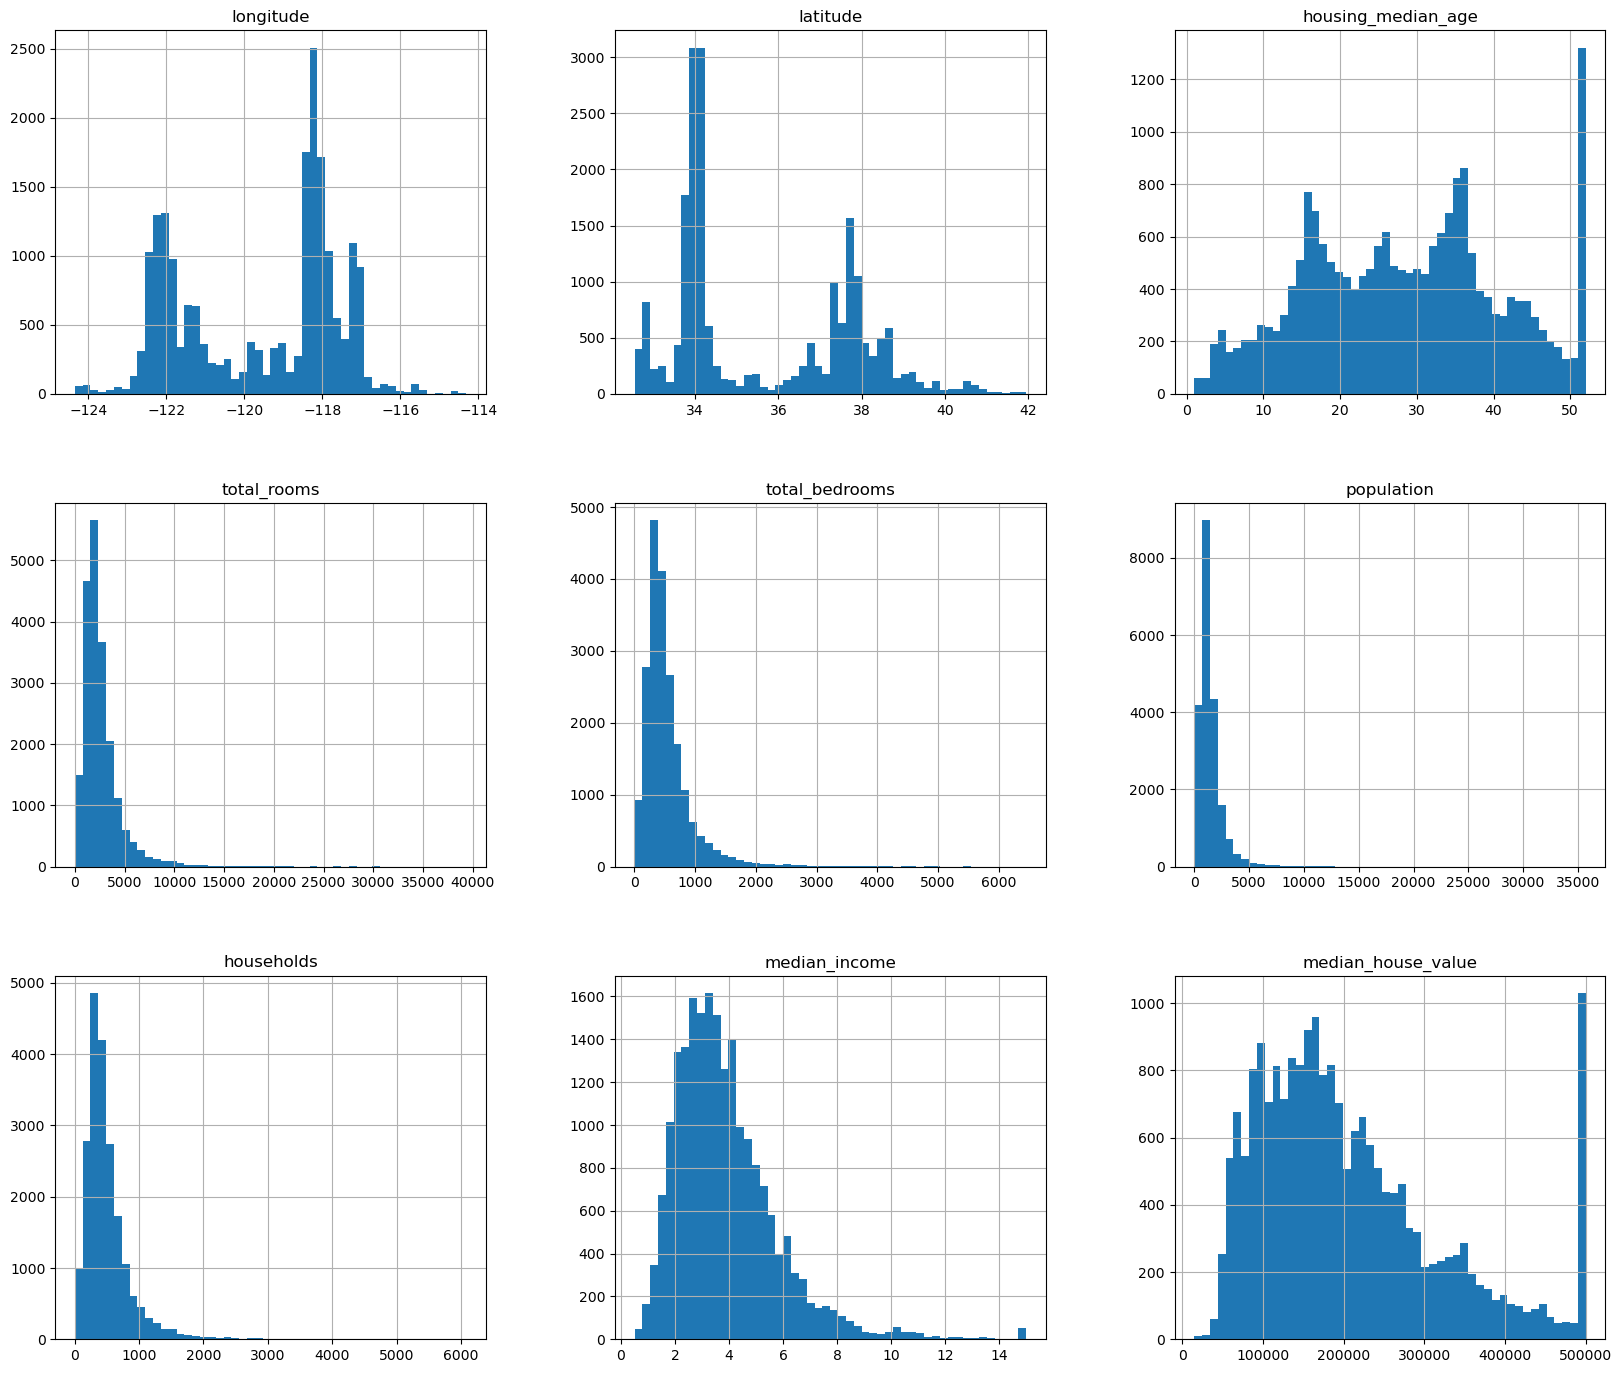

In [11]:
df.hist(bins=50, figsize=(20,17))
plt.show()

## hozir tepada oxirgi vizualizatsiya usib ketdi buni sababi 60 70 yillik uylarni ham 50yil deb belgilab quyishgan sabab shu
## biz buni nima qilishimiz mumkin keling oldin normal destributsiyani koraylik

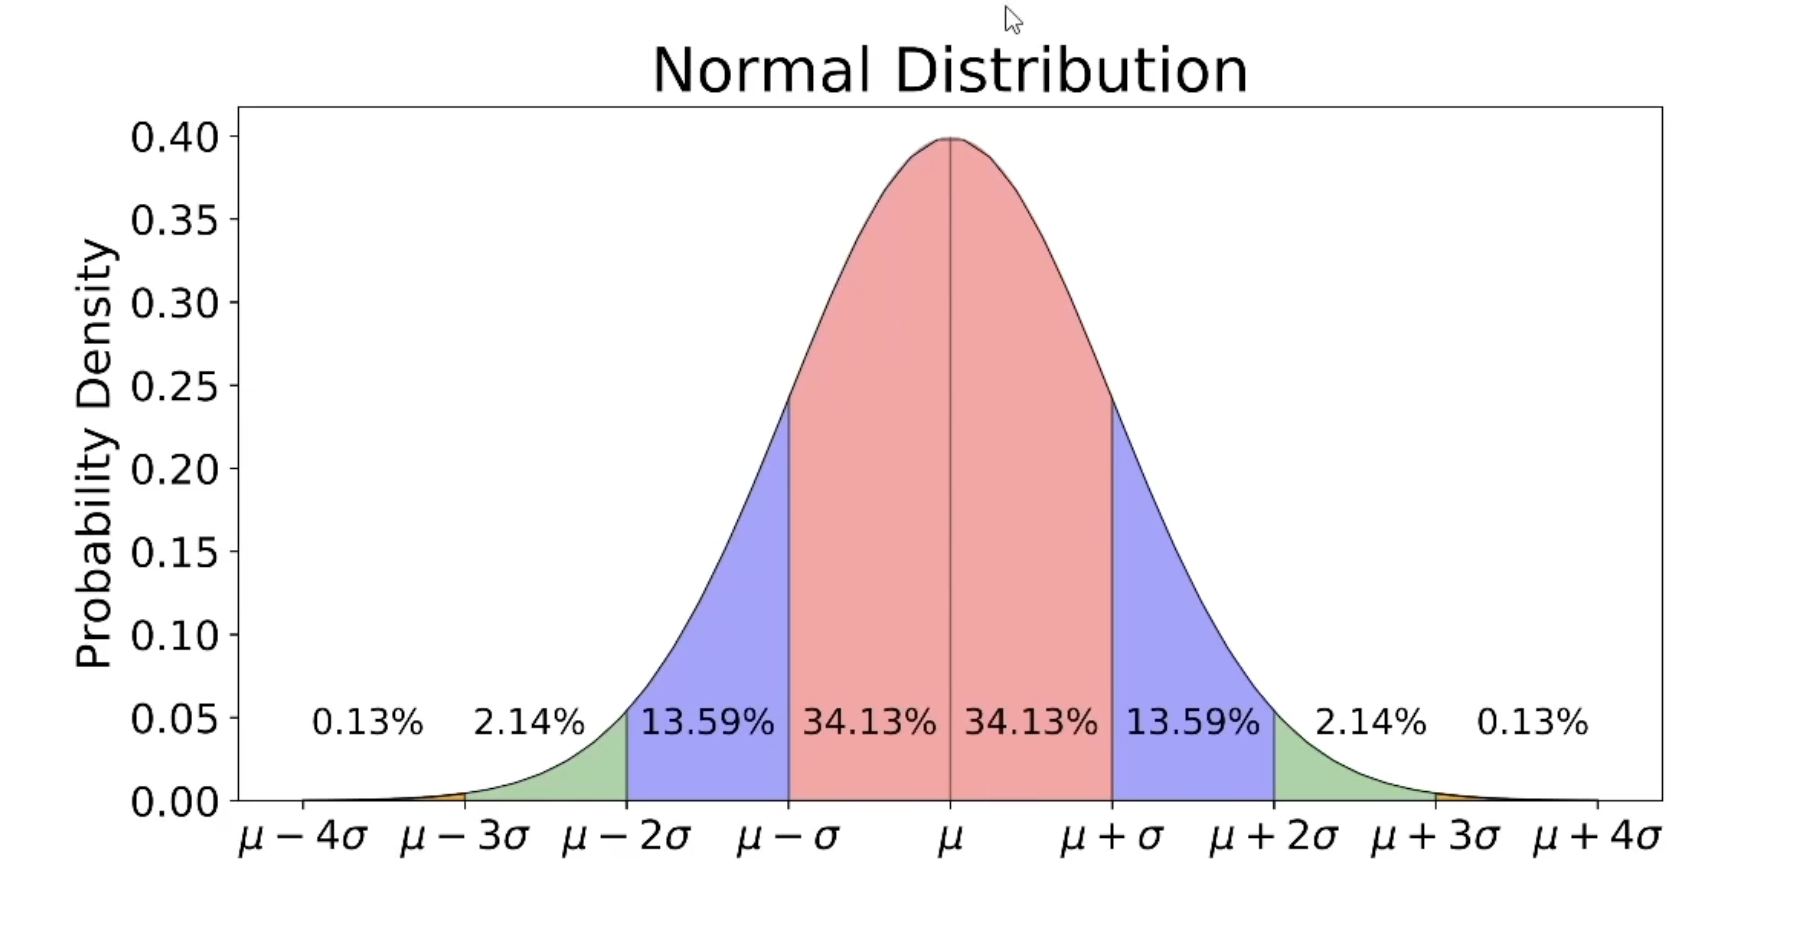

In [13]:
Image('normal_destributsiya.png')

## random_state - bizga datani bir marta aralashtirib keyin ozgarmaydigan qilib beradi 
## datani bir marta bulganda qanday qiymatlar olgan bolsa usha holatida data qotadi

In [14]:
from sklearn.model_selection import train_test_split
train_set, test_set = train_test_split(df, test_size=0.2, random_state=12)

In [16]:
train_set.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
1652,-121.97,37.93,4.0,3241.0,464.0,1552.0,494.0,6.6134,307000.0,INLAND
14652,-117.15,32.80,41.0,1413.0,261.0,1070.0,259.0,2.3578,166700.0,NEAR OCEAN
3548,-118.61,34.25,16.0,8295.0,1506.0,3903.0,1451.0,5.5111,276600.0,<1H OCEAN
6730,-118.14,34.11,52.0,2742.0,422.0,1153.0,414.0,8.1124,500001.0,<1H OCEAN
18445,-121.81,37.25,25.0,4096.0,623.0,2128.0,618.0,6.2957,251800.0,<1H OCEAN


## tasavvur qilaylik data yigganimizda 60% erkak 40% ayol qatnashdi biz datani bulganda ham huddi shunday qilmoqchimiz lekin train_test_split bu narsalarga qaramay bulib tashhlaydi

## bu vaziyatda bizga 

In [17]:
from sklearn.model_selection import StratifiedShuffleSplit

## buni sinash uchun income datani kategoriyalarga bulib olamiz

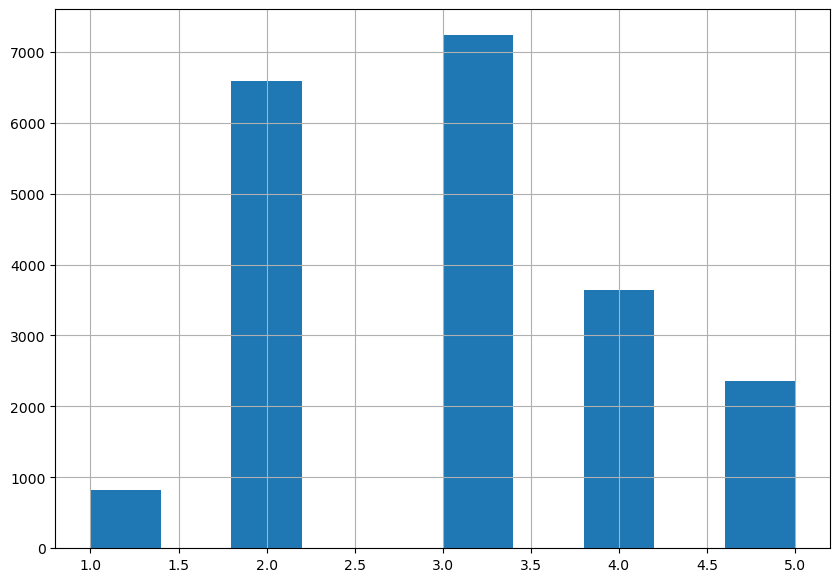

In [20]:
df['income_cat'] = pd.cut(df['median_income'], bins=[0., 1.5, 3.0, 4.5, 6.0, np.inf], labels=[1,2,3,4,5])
df['income_cat'].hist(figsize=(10,7))
plt.show()


## Stretified sal boshqacha ishlaydi bu datani balansini ushlab qoladi yani bu vizualizatsiyada eng kattasi 3 busa bulganimizda ham 3 chiqadi lekin stretified bizga data emas index qaytaradi shu uchun biz silk yozib quyamiz

In [22]:
from sklearn.model_selection import StratifiedShuffleSplit
statifid = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=32)
for train_index, test_index in statifid.split(df, df['income_cat']):
    strat_train = df.loc[train_index]
    strat_test = df.loc[test_index]

## mana korib turibsiz biz balansni saqlab qoldik

<Axes: >

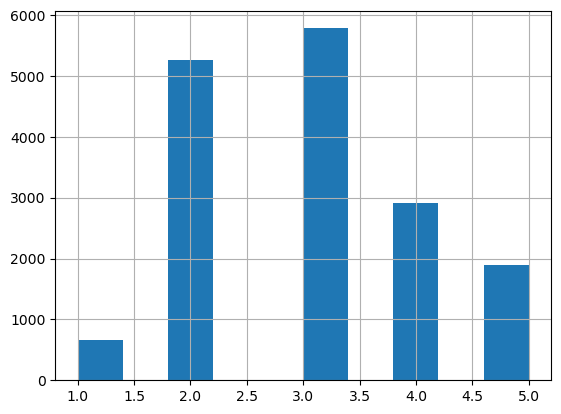

In [24]:
strat_train['income_cat'].hist()

# edni income_cutni uchiramiz biz sinash uchun ishlatib kordik

In [25]:
strat_train.drop('income_cat', axis=1, inplace=True)
strat_test.drop('income_cat', axis=1, inplace=True)

## endi train datamizni addelni dataga kochirib olamiz chunki biz uni ustida amallar bajaramiz

In [26]:
housing = strat_train.copy()
housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
5242,-118.40,34.11,32.0,5578.0,753.0,1567.0,697.0,15.0001,500001.0,<1H OCEAN
18762,-122.25,40.66,15.0,2771.0,546.0,1423.0,505.0,3.6413,108500.0,INLAND
10729,-117.87,33.60,20.0,3212.0,572.0,1064.0,526.0,6.6155,500001.0,<1H OCEAN
17547,-121.88,37.34,52.0,867.0,232.0,1264.0,227.0,2.6312,302900.0,<1H OCEAN
3337,-122.51,38.76,9.0,2589.0,482.0,1050.0,374.0,4.0435,132600.0,INLAND


## xaritani chiqaramiz vizualizastiya chiqganida aniq korinishi uchun

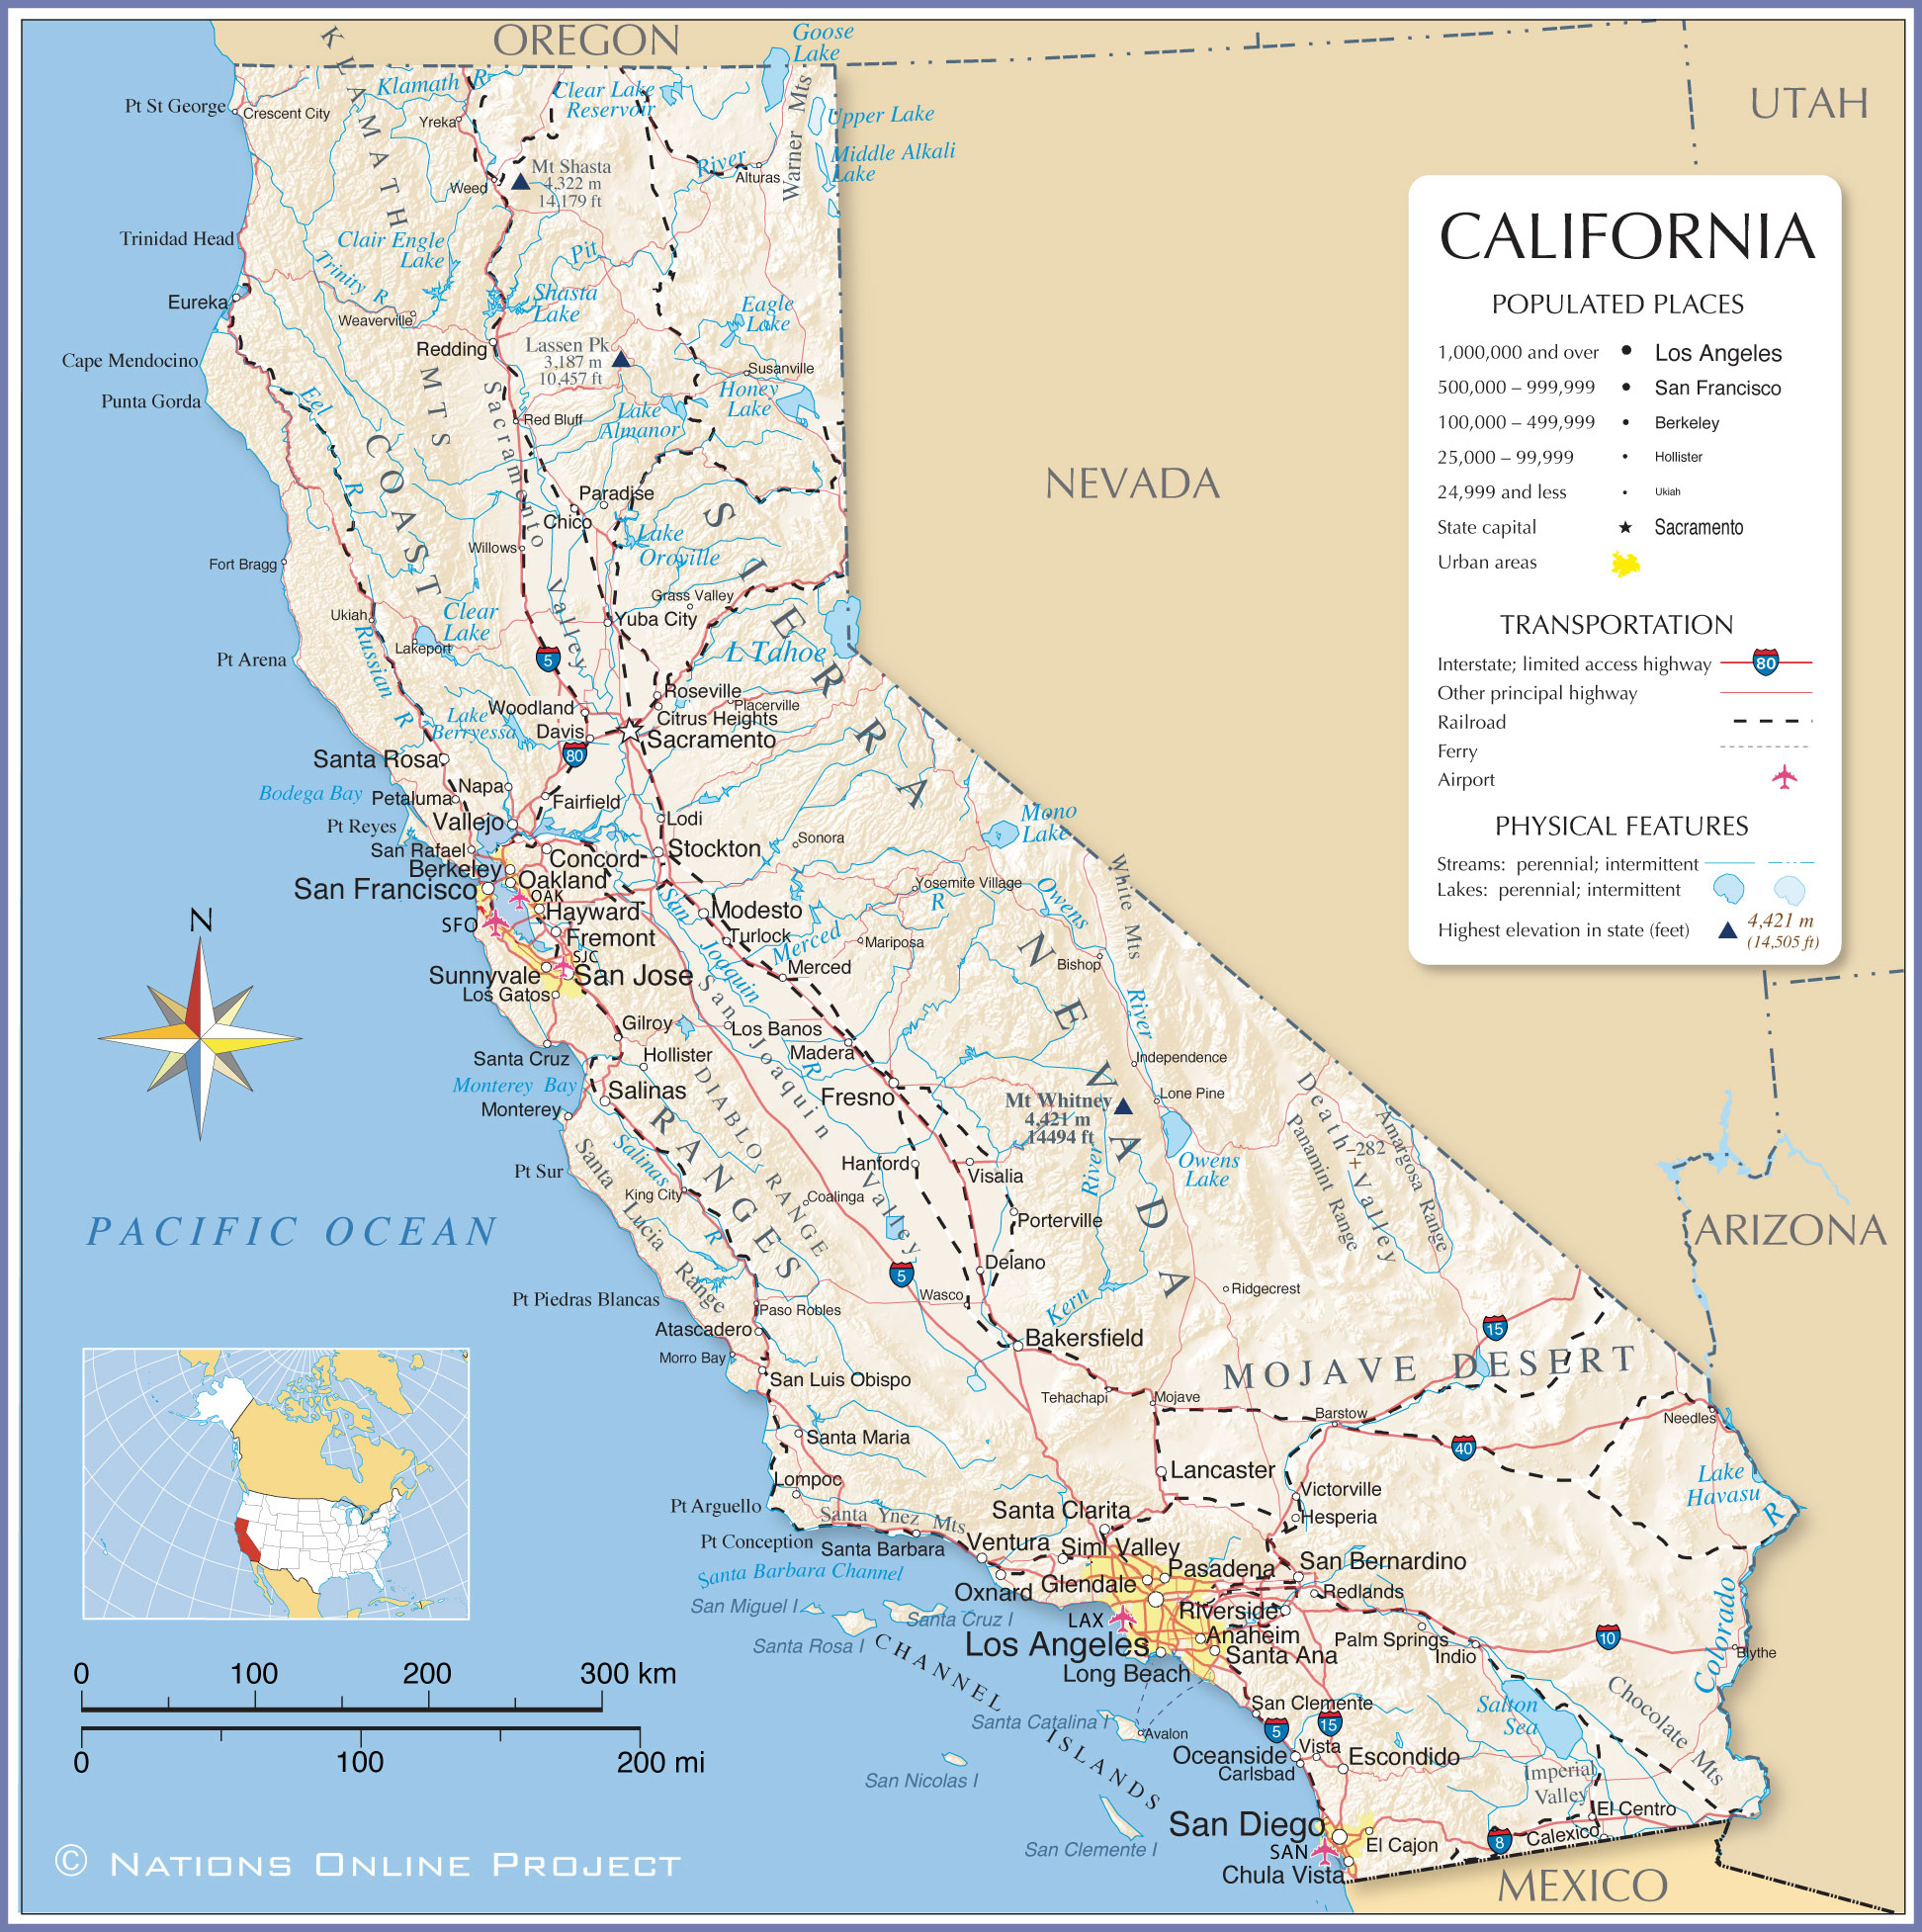

In [29]:
Image('California_map.jpg', width=500)

<Axes: xlabel='longitude', ylabel='latitude'>

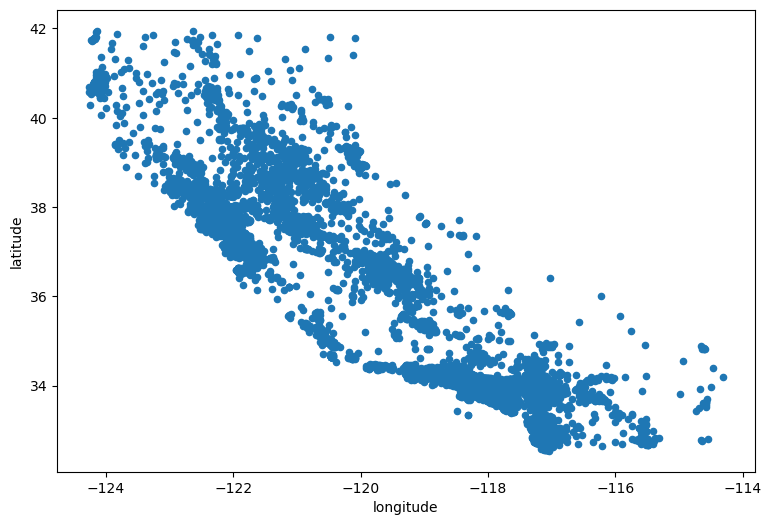

In [31]:
housing.plot(kind='scatter', x='longitude',y='latitude', figsize=(9,6))

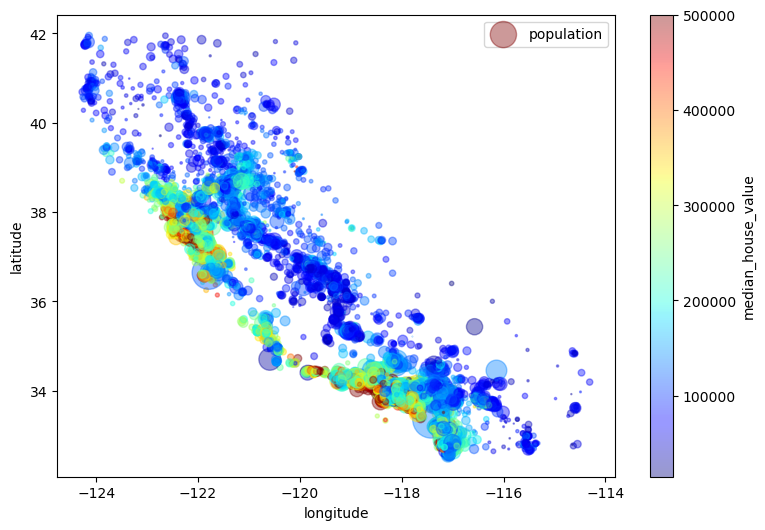

In [34]:
housing.plot(kind='scatter',
            x='longitude',
            y='latitude', 
            figsize=(9,6),
            alpha=0.4,
            s=housing['population']/50,
            label='population',
            c='median_house_value',
            cmap='jet',
            colorbar=True,
            )
plt.show()

## askending false bu kamayish tartibida sortlaydi

In [35]:
housing.corrwith(housing['median_house_value']).sort_values(ascending=False)

/var/folders/5r/8qsc7qzj04g73js6m7szr_7h0000gn/T/ipykernel_16165/877251570.py:1: FutureWarning: The default value of numeric_only in DataFrame.corrwith is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  housing.corrwith(housing['median_house_value']).sort_values(ascending=False)


median_house_value    1.000000
median_income         0.684216
total_rooms           0.133887
housing_median_age    0.111445
households            0.066193
total_bedrooms        0.050271
population           -0.026870
longitude            -0.043955
latitude             -0.145869
dtype: float64

## mana korishimiz mumkin uylarni narxiga odamlarni oyligini tasiri juda katta ekan odamlar kopligi unchalik tasiri yoq uylarni narxiga

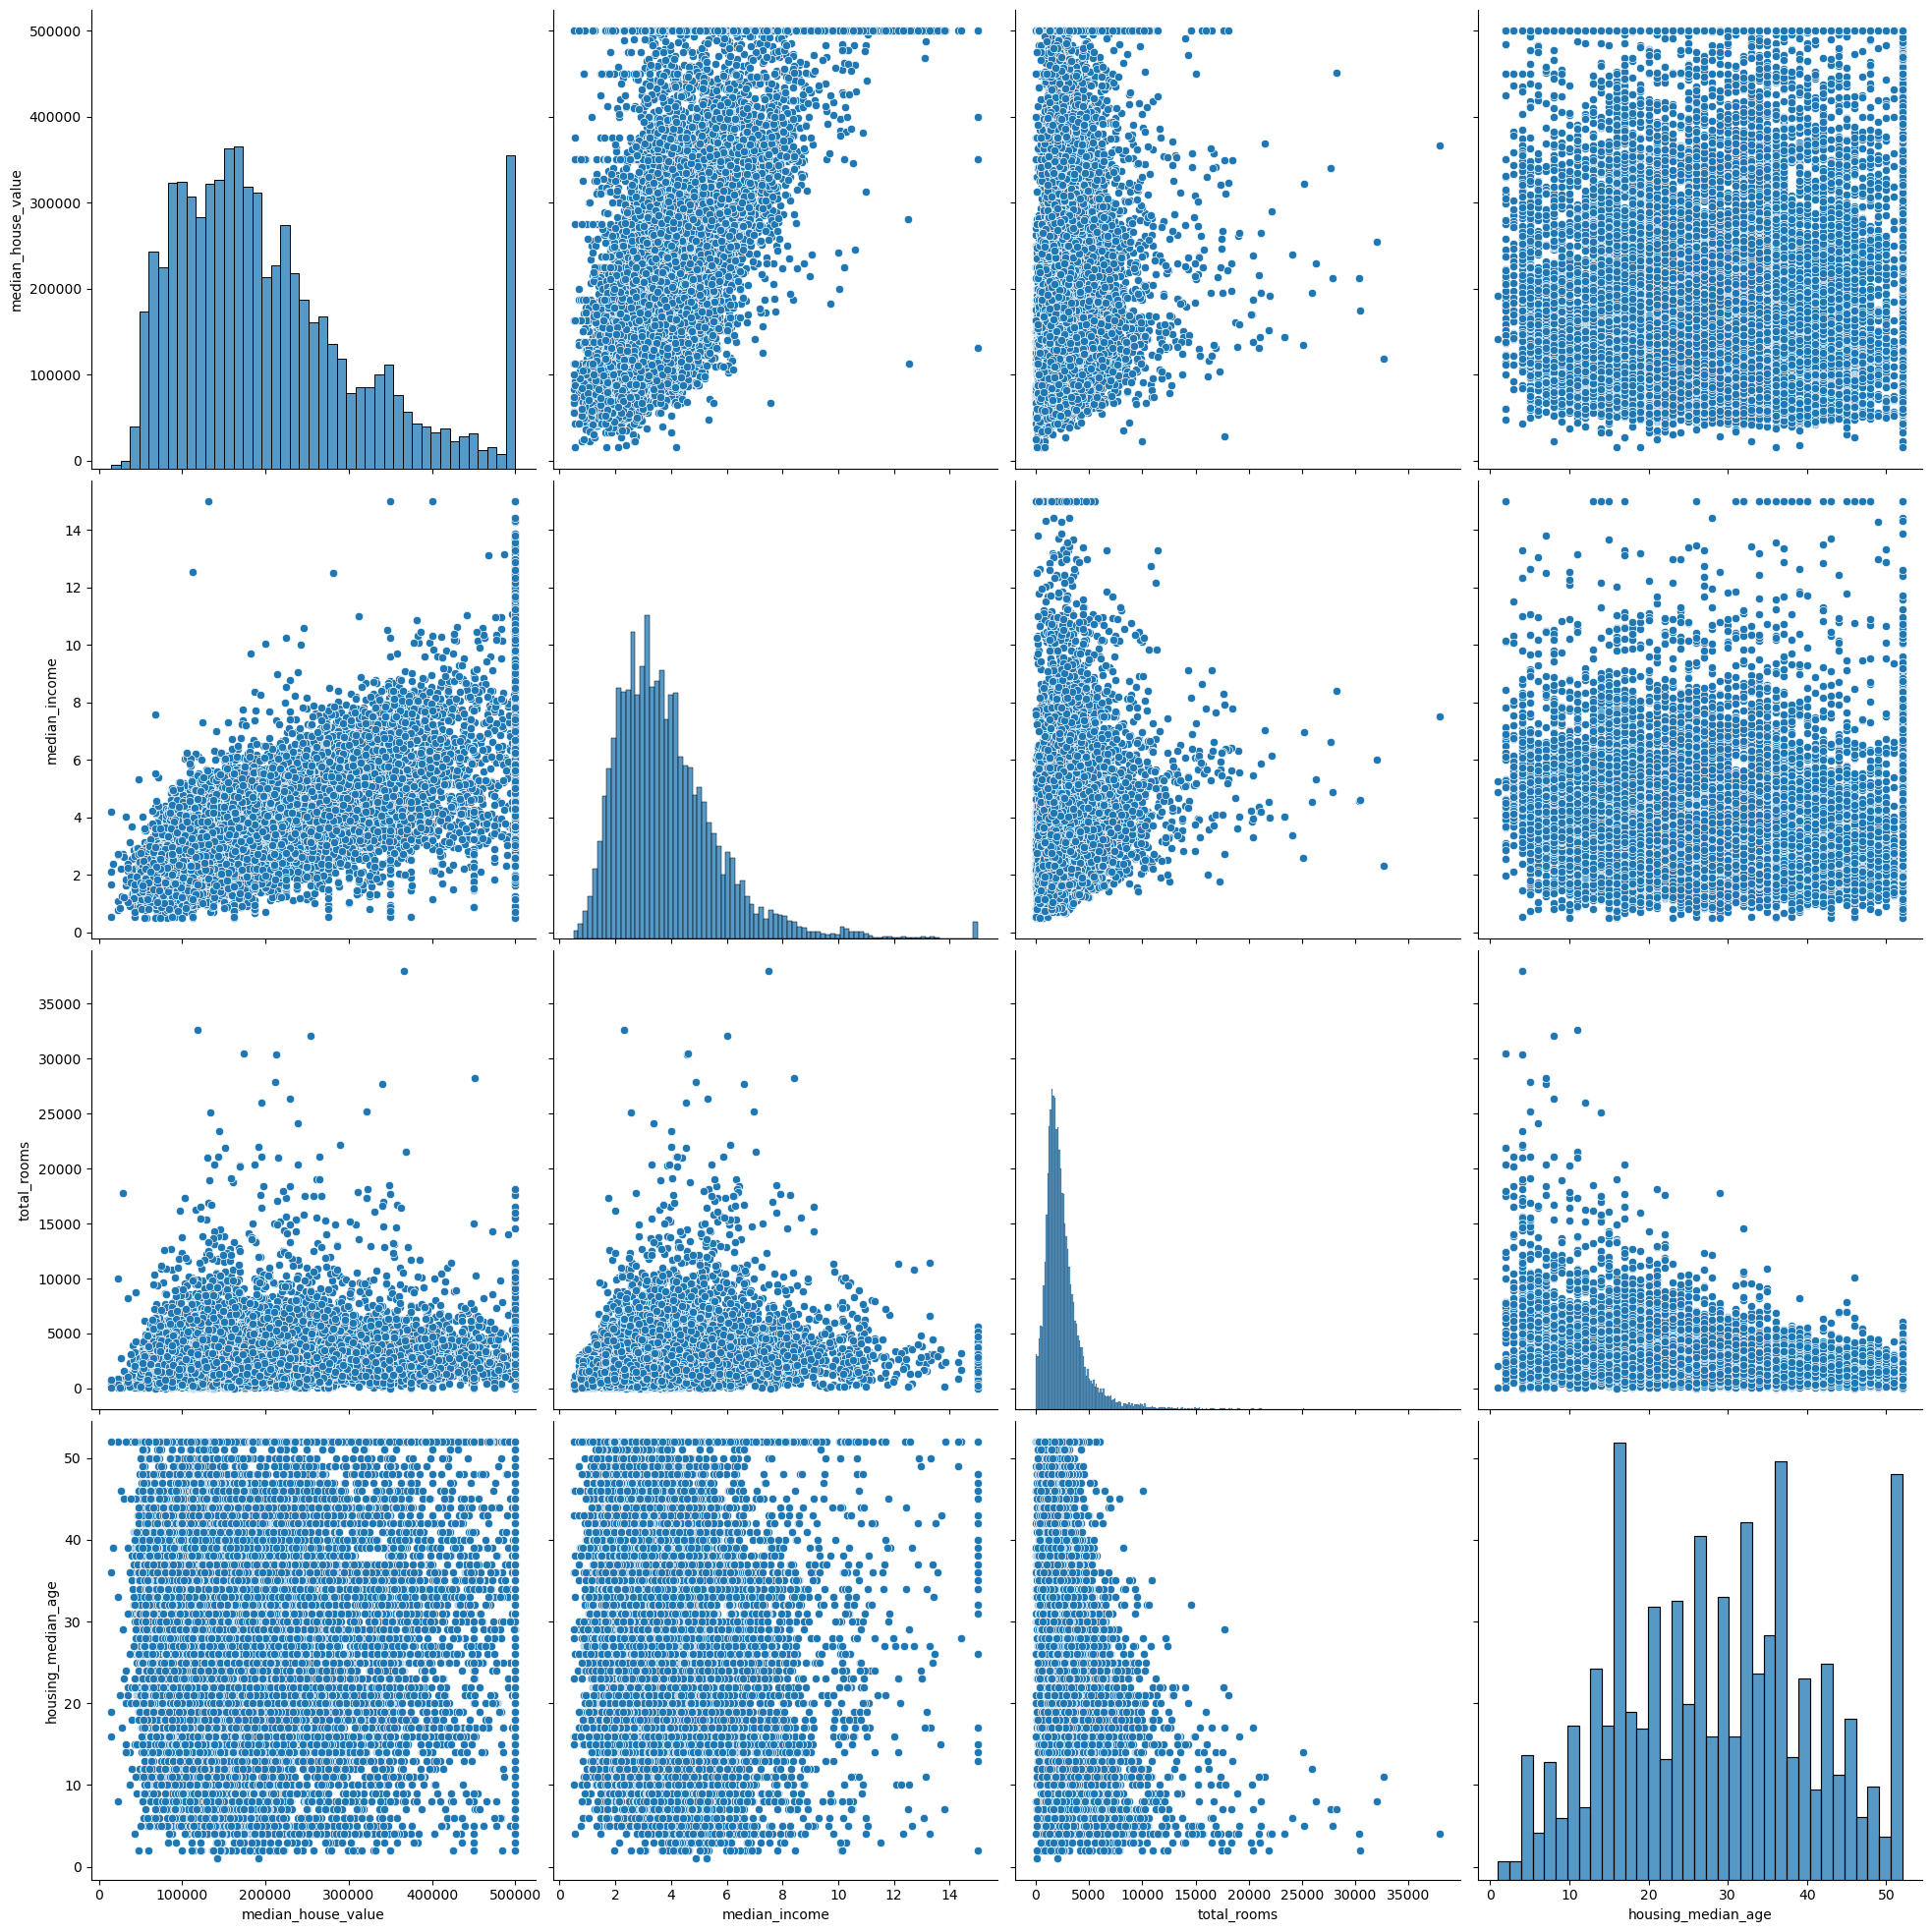

In [36]:
cols = ['median_house_value','median_income','total_rooms','housing_median_age']
sns.pairplot(housing[cols], height=5)
plt.show()

## endi biz kordik bu yerda odamlarni oyligi uylarni narxiga tasir qilyapti qolgan data unchayam tasiri yoq biz data science sifatida bunga yechim yani bor datadan yangi data yaratishimiz kerak

<h5> masalan bizda uylarni nechtaligi va oilalar soni bor bularni bulsak har bir oilaga nechtadan honadon togri kelayotganini topamiz bu ham bizga yordam beradi uziga toq oila nisbata katta kambagallar esa zichroq yashashadi

In [37]:
housing['rooms_per_household'] = housing['total_rooms']/housing['households']
housing['bedrooms_per_rooms'] = housing['total_bedrooms']/housing['total_rooms']
housing['population_per_household'] = housing['population']/housing['households']

In [39]:
housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_household,bedrooms_per_rooms,population_per_household
5242,-118.40,34.11,32.0,5578.0,753.0,1567.0,697.0,15.0001,500001.0,<1H OCEAN,8.002869,0.134995,2.248207
18762,-122.25,40.66,15.0,2771.0,546.0,1423.0,505.0,3.6413,108500.0,INLAND,5.487129,0.197041,2.817822
10729,-117.87,33.60,20.0,3212.0,572.0,1064.0,526.0,6.6155,500001.0,<1H OCEAN,6.106464,0.178082,2.022814
17547,-121.88,37.34,52.0,867.0,232.0,1264.0,227.0,2.6312,302900.0,<1H OCEAN,3.819383,0.267589,5.568282
3337,-122.51,38.76,9.0,2589.0,482.0,1050.0,374.0,4.0435,132600.0,INLAND,6.922460,0.186172,2.807487


## endi biz yangi qiymat qushdik korrelatsiyani chiqarib korishimiz mumkin

In [40]:
housing.corrwith(housing['median_house_value']).sort_values(ascending=False)

/var/folders/5r/8qsc7qzj04g73js6m7szr_7h0000gn/T/ipykernel_16165/877251570.py:1: FutureWarning: The default value of numeric_only in DataFrame.corrwith is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  housing.corrwith(housing['median_house_value']).sort_values(ascending=False)


median_house_value          1.000000
median_income               0.684216
rooms_per_household         0.166727
total_rooms                 0.133887
housing_median_age          0.111445
households                  0.066193
total_bedrooms              0.050271
population                 -0.026870
population_per_household   -0.033058
longitude                  -0.043955
latitude                   -0.145869
bedrooms_per_rooms         -0.250116
dtype: float64

## mana qanchalik yaqinligini kordik minus busayam birga yaqin busa bu juda zur degani edi hozir bizda badrooms_per_rooms huddi shunday natija berdi

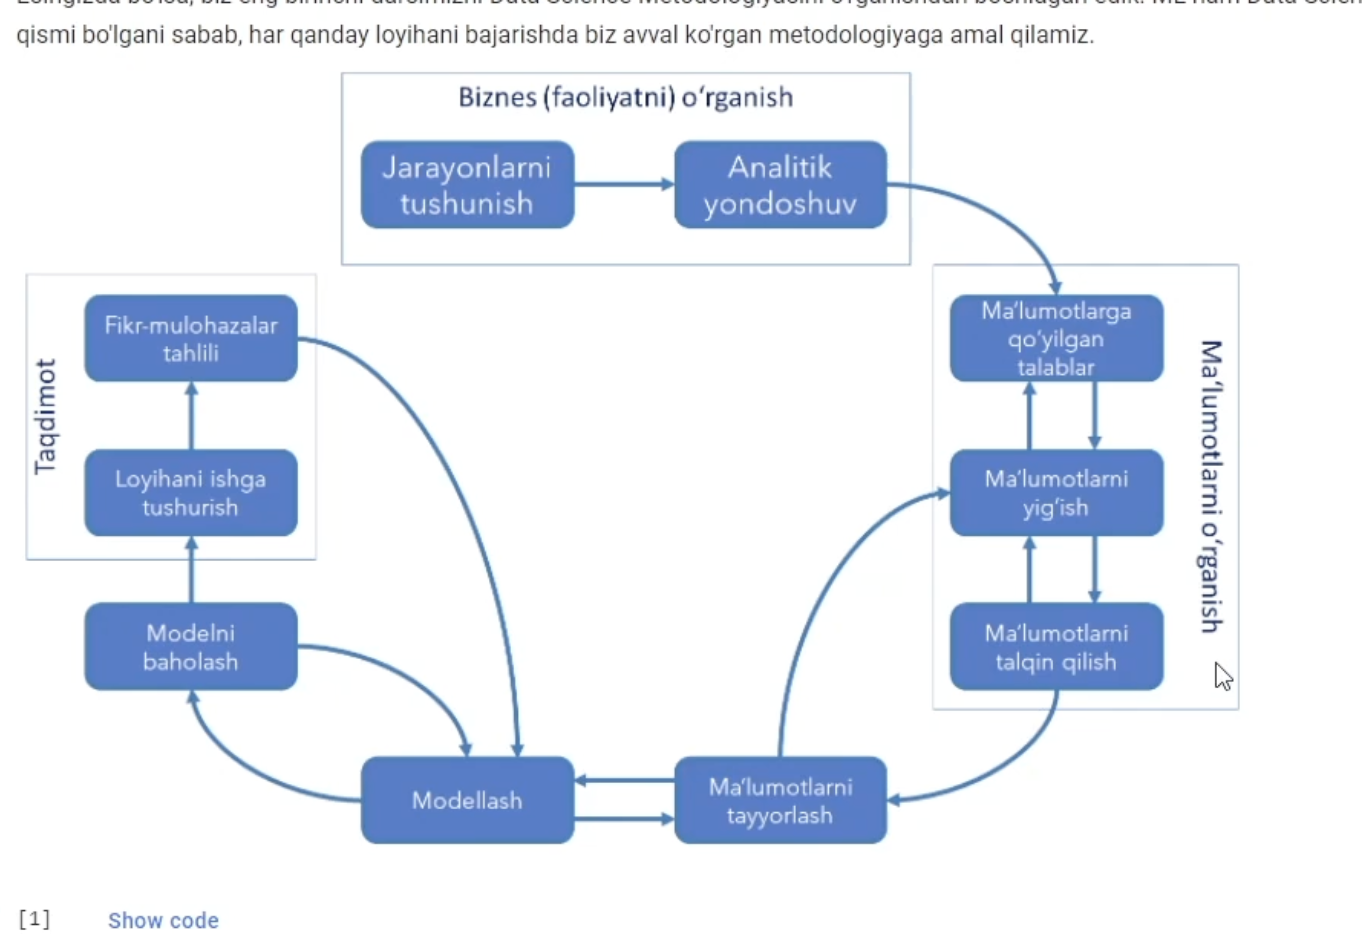

In [41]:
Image('map.png')

## edni biz malumotlarni tayyorlash bosqichiga ham yetib keldik 

# ML ga tayyorlash